# $p_T$ model discrimination with narrow $Z^\prime$ and SM truth
Use `active_fake_data` to choose a BSM synthetic dataset (normal mass/coupling fits) or `SM` to compare against the four **fixed** BSM benchmarks. For SM truth only the shape/profile-likelihood (`Z_sh`) is defined; normalized signed falloff (`Z_fa`) is unavailable. The narrow $Z^\prime$ template uses the 1%-width MC and its configured nominal coupling scale.

**Benchmark couplings:** edit `DEFAULT_FAKE_SCALES` in `helpers.py`. They apply to both BSM truth and SM truth; saved workspace scales are ignored. Rerun the import and analysis cells after editing `helpers.py`.


In [19]:
import sys
import importlib
import os
import urllib.request
import pandas as pd
import numpy as np
import scipy.stats as stats
from scipy.optimize import minimize
import matplotlib.pyplot as plt
from pathlib import Path
from itertools import combinations
import matplotlib.lines as mlines
import matplotlib.gridspec as gridspec
import matplotlib.colors as mcolors
import warnings
warnings.filterwarnings('ignore')
import glob
import gc
import seaborn as sns
import math
import gzip
import pickle

sys.path.append('./../')
import helpers as hp
importlib.reload(hp)  # Reload DEFAULT_FAKE_SCALES after edits to helpers.py
print('Using helpers from:', hp.__file__)


pd.options.mode.chained_assignment = None
plt.rcParams['figure.max_open_warning'] = 50
plt.rcParams.update({
    "text.usetex": True,
    "font.family": "sans-serif",
    "font.sans-serif": ["Helvetica"],
    "savefig.dpi": 300
})
plt.rcParams['text.latex.preamble'] = r'\usepackage{amsmath}'

sns.set_style('ticks', {'font.family': 'Times New Roman', 'font.serif': 'Times New Roman'})
sns.set_context('paper', font_scale=2.0)


colors = plt.cm.tab10.colors
color_map = {
    'SM': 'gray',
    'VLF': colors[2],
    'Scalar': colors[0],
    'Zprime': colors[3],
    'Zprime_20pc': 'firebrick',
    'FakeData': 'black'
}


# Dictionaries for styling
pair_colors = {"Scalar vs VLF": "#1f77b4", "Scalar vs Zprime": "#2ca02c", "VLF vs Zprime": "#d62728"}
class_colors = {"Scalar": "blue", "VLF": "green", "Zprime": "red"}
pair_latex = {"Scalar vs VLF": r"Scalar vs VLF", "Scalar vs Zprime": r"Scalar vs $Z^\prime$", "VLF vs Zprime": r"VLF vs $Z^\prime$"}
class_latex = {"Scalar": r"Scalar", "VLF": r"VLF", "Zprime": r"$Z^\prime$"}
syst_styles = {0.00: ("black", "-"), 0.02: ("#1f77b4", "--"), 0.05: ("#ff7f0e", "-."), 0.10: ("#d62728", ":")}
eps_styles = {
    0.0: ('-', 'D'),
    0.02: ("-.", "o"),
    0.05: ("--", "s"),
    0.10: (":", "^")
}



plt.rcParams['text.latex.preamble'] = r'\usepackage{amsmath}'
plt.rcParams['figure.max_open_warning'] = 50
pd.option_context('display.max_columns', -1)


pd.options.mode.chained_assignment = None #Disable copy warnings


#Define plotting style:
sns.set() #Set style
sns.set_style('ticks',{'font.family':'Times New Roman', 'font.serif':'Times New Roman'})
sns.set_context('paper', font_scale=1.9, rc={
    "axes.labelsize": 19,
    "axes.titlesize": 19,
    "legend.title_fontsize": 14,
    "legend.fontsize": 13,
})
cm = plt.colormaps['RdYlBu']

Using helpers from: /home/vinicius/Documents/backup_Unf/UnfoldingBSMttbar/Plots/helpers.py


In [ ]:
# Configuration: standard fitted-model comparisons or SM versus fixed benchmarks.
# Change benchmark couplings ONLY in helpers.py -> DEFAULT_FAKE_SCALES.
# The workspace does not override them; this notebook passes no fake_scales.
workspace_file = 'pT_mass_scan_13_6TeV_hists.pkl'
mass_source = 'best_fit_mc'  # 'grid' or 'best_fit_mc' for ordinary BSM fake data
refit_scale = True
refit_zprime_scale = False
analysis_range = (500, 3600)
systematics = [0.00]
luminosities = np.array([300, 500, 1000, 1500, 2000, 2500, 3000])

# BSM options: Scalar_1500, VLF_1500, Zprime_3000 (broad),
# Zprime_1pc_3000 (narrow).  SM uses NO fitted parameters.
active_fake_data = 'VLF_1500'  # 'SM', 'Scalar_1500', 'VLF_1500', 'Zprime_3000', 'Zprime_1pc_3000'

with open(workspace_file, 'rb') as handle:
    workspace = pickle.load(handle)
benchmark_keys = [key for key in workspace['FakeData'] if key != 'SM']
fit_hypothesis_labels = ['Scalar', 'VLF', 'Zprime', 'Zprime_20pc', 'SM']

# Narrow Z' needs separately generated best-fit MC to use that option.
# Until these exist, use the available mass grid (the same as other first-pass fits).
def select_mass_source(fake_key):
    if fake_key == 'SM':
        return 'fixed_benchmarks'
    if mass_source == 'best_fit_mc' and fake_key == 'Zprime_1pc_3000':
        by_model = workspace.get('BestFitSamples', {}).get(fake_key, {})
        required = ('Scalar', 'VLF', 'Zprime', 'Zprime_20pc')
        if any(not by_model.get(model) for model in required):
            print('Narrow Zprime: best-fit MC incomplete; using the mass grid.')
            return 'grid'
    return mass_source


def make_fitted_data(fake_key, lum):
    selected_source = select_mass_source(fake_key)
    return hp.fit_and_assemble_data(
        fake_data_key=fake_key,
        workspace_file=workspace_file,
        sys_err_list=systematics,
        lumi=float(lum),
        observable='pT',
        analysis_range=analysis_range,
        mass_source='grid' if fake_key == 'SM' else selected_source,
        refit_best_fit_scale=refit_scale,
        refit_zprime_best_fit_scale=refit_zprime_scale,
    )


fitted_data_by_lumi = {}
for lum in luminosities:
    print(f'Processing {active_fake_data} for lumi = {lum} fb^-1')
    fitted_data_by_lumi[lum] = make_fitted_data(active_fake_data, lum)


Processing VLF_1500 for lumi = 300 fb^-1

Fitting observable: pT
Analysis range: 500 <= pT < 3600 GeV
Systematic error: 0.0%
VLF         : selected mass = 1500.000 GeV | parabolic estimate = 1505.297 GeV | scale = 3.7997245 | min q = 0.00195106 | source = grid
Scalar      : selected mass = 1200.000 GeV | parabolic estimate = 1246.660 GeV | scale = 5.6482868 | min q = 0.53587 | source = grid
Zprime      : selected mass = 2900.000 GeV | parabolic estimate = 2907.752 GeV | scale = -0.40899502 | min q = 13.2336 | source = grid
Zprime_20pc : selected mass = 2800.000 GeV | parabolic estimate = 2811.446 GeV | scale = -3.6362243 | min q = 5.62459 | source = grid
FakeData    : nominal mass = 1500.0 GeV | scale = 3.8
Synthetic signal yield in fit window: 2080.12 events
Processing VLF_1500 for lumi = 500 fb^-1

Fitting observable: pT
Analysis range: 500 <= pT < 3600 GeV
Systematic error: 0.0%
VLF         : selected mass = 1500.000 GeV | parabolic estimate = 1505.297 GeV | scale = 3.7997225 | min 

In [21]:
def plot_sm_truth_benchmarks(fit_data, lum, rng=(500, 3600), outfile=None):
    """Plot SM Asimov expectation versus FIXED benchmark total yields.

    Top: SM and SM + NP expected counts. Bottom: signed BSM excess / SM.
    This is distinct from a fitted signal-only comparison.
    """
    bins = np.asarray(fit_data['bins'], dtype=float)
    mask = (bins[:-1] >= rng[0]) & (bins[:-1] < rng[1])
    indices = np.flatnonzero(mask)
    if not len(indices) or not np.array_equal(indices, np.arange(indices[0], indices[-1] + 1)):
        raise ValueError('Requested histogram window must contain contiguous bins.')
    edges = bins[indices[0]:indices[-1] + 2]
    hists = fit_data['hists']
    n_sm = np.asarray(hists['SM'])[mask] * lum * 1000.0

    fig, (ax_main, ax_ratio) = plt.subplots(
        2, 1, figsize=(11, 9), sharex=True,
        gridspec_kw={'height_ratios': [2, 1], 'hspace': 0.08}
    )
    ax_main.stairs(n_sm, edges, color='black', lw=2.5, label='SM (Asimov truth)')
    colors_local = plt.cm.tab10.colors
    for idx, key in enumerate(fit_data['benchmark_labels']):
        pure = np.asarray(hists[key])[mask]
        interference = np.asarray(hists.get(f'{key}_int', 0.0))
        if interference.ndim:
            interference = interference[mask]
        delta_n = (pure + interference) * lum * 1000.0
        total = n_sm + delta_n
        color = colors_local[idx % len(colors_local)]
        if np.any(total <= 0):
            raise ValueError(f'Nonpositive total expected yield for {key}.')
        ax_main.stairs(total, edges, color=color, lw=2, label=key)
        rel_excess = np.divide(delta_n, n_sm, out=np.full_like(delta_n, np.nan), where=n_sm > 0)
        ax_ratio.stairs(rel_excess, edges, color=color, lw=2)

    ax_main.set_yscale('log')
    ax_main.set_ylabel('Expected events')
    ax_main.set_title(rf'SM truth vs fixed benchmarks, $\mathcal{{L}}={lum:g}$ fb$^{{-1}}$')
    ax_main.legend(frameon=False, fontsize=12)
    ax_ratio.axhline(0, color='black', lw=1, alpha=0.6)
    ax_ratio.set_ylabel(r'$N_{\rm BSM}/N_{\rm SM}$')
    ax_ratio.set_xlabel(r'$p_T$ [GeV]')
    ax_ratio.set_xlim(*rng)
    ax_ratio.grid(alpha=0.2)
    plt.tight_layout()
    if outfile:
        fig.savefig(outfile, dpi=300, bbox_inches='tight')
    plt.show()




# Plot the best fit distributions

Scalar (Best Fit) 3075.0907619419386
VLF (Best Fit) 3469.190756155377
$Z^\prime$ Narrow (Best Fit) 378.55956637197585
$Z^\prime$ Broad (Best Fit) 1322.2665738870915
Plot saved successfully as: Dists_VLFAsimov.png


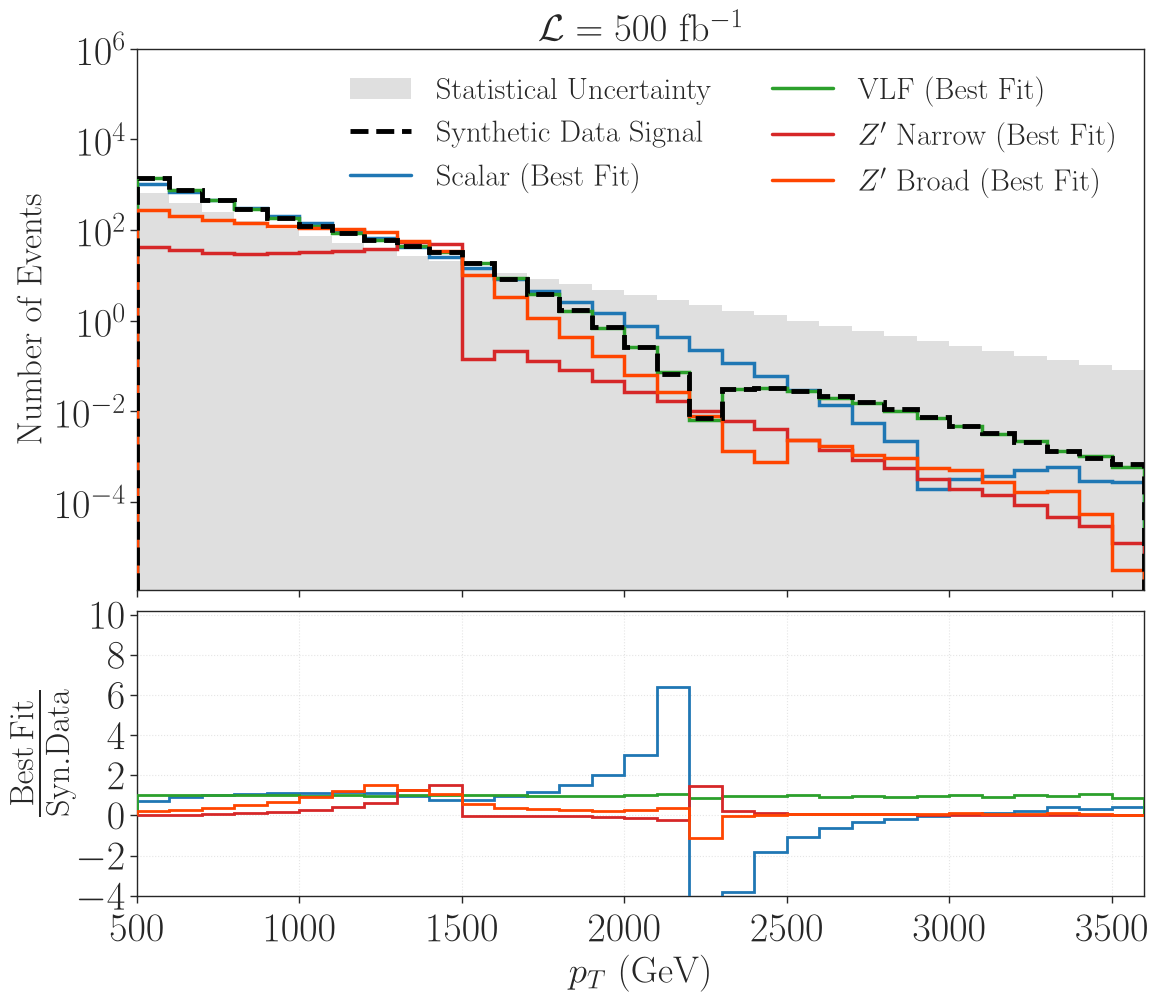

In [22]:
def plot_raw_weighted_histograms_lite(fit_data, lum=3000.0, sys_err=0.0, var="m_tt", rng=(1200, 5000), density=False):
    """
    Plots best-fit distributions and ratios directly from pre-binned histograms
    using matplotlib's `ax.stairs`.
    """
    hists = fit_data['hists']
    raw_bin_edges = np.array(fit_data['bins'])

    # Filter bins and bin edges according to rng
    bin_centers = 0.5 * (raw_bin_edges[:-1] + raw_bin_edges[1:])
    bin_mask = (bin_centers >= rng[0]) & (bin_centers <= rng[1])

    selected_left_edges = raw_bin_edges[:-1][bin_mask]
    selected_right_edge = raw_bin_edges[1:][bin_mask][-1:]
    bin_edges = np.concatenate([selected_left_edges, selected_right_edge])

    colors = plt.cm.tab20.colors
    color_map = {
        'SM': 'gray',
        'VLF (Best Fit)': colors[4],
        'Scalar (Best Fit)': colors[0],
        'Zprime': colors[6],
        'Zprime_20pc': 'orangered',
        'FakeData': 'black',
        r'$Z^\prime$ Broad (Best Fit)': 'orangered',
        r'$Z^\prime$ Narrow (Best Fit)': colors[6],
        'Pseudo Dataset': 'black'
    }

    hist_data = {}

    #  Process SM
    h_sm = hists['SM'][bin_mask] * lum * 1000.0
    hErr_sm_poisson = np.sqrt(np.abs(h_sm))
    hErr_sm = np.sqrt(np.abs(h_sm) + (sys_err * h_sm)**2)
    hist_data['SM'] = {'h': h_sm, 'err': hErr_sm, 'err_poisson': hErr_sm_poisson, 'lbl': "SM"}

    # Process BSM & FakeData Models
    target_models = ['FakeData', 'Scalar', 'VLF', 'Zprime', 'Zprime_20pc']

    for model_key in target_models:
        if model_key not in hists:
            continue

        # Combine pure cross-section + interference (if present) and convert to yield
        h_xsec = hists[model_key][bin_mask].copy()
        if f"{model_key}_int" in hists:
            h_xsec += hists[f"{model_key}_int"][bin_mask]

        h = h_xsec * lum * 1000.0
        err = np.sqrt(np.abs(h))

        # Map display labels
        if model_key == 'Zprime_20pc':
            display_lbl = r'$Z^\prime$ Broad (Best Fit)'
        elif model_key == 'Zprime':
            display_lbl = r'$Z^\prime$ Narrow (Best Fit)'
        elif model_key == 'Scalar':
            display_lbl = 'Scalar (Best Fit)'
        elif model_key == 'VLF':
            display_lbl = 'VLF (Best Fit)'
        else:
            display_lbl = 'FakeData'

        hist_data[display_lbl] = {'h': h, 'err': err, 'lbl': display_lbl, 'raw_key': model_key}

    # ------------------------------------------------------------
    # Setup Figure (Main Panel + Ratio Panel)
    # ------------------------------------------------------------
    fig, (ax_main, ax_ratio) = plt.subplots(2, 1, figsize=(13, 11), sharex=True,
                                            gridspec_kw={'height_ratios': [1.9, 1], 'hspace': 0.05})

    for lab_str, data in hist_data.items():
        c = color_map.get(lab_str, color_map.get(data.get('raw_key'), 'gray'))

        if data.get('raw_key') == 'FakeData':
            ax_main.stairs(np.abs(data['h']), bin_edges, linewidth=3.5, linestyle='--',
                           label='Synthetic Data Signal', color='black', zorder=4)
        elif lab_str == 'SM':
            # Draw Shaded Poisson Uncertainty Band
            ax_main.stairs(np.sqrt(data['h'] + hist_data['FakeData']['h']), bin_edges, fill=True,
                           color=c, alpha=0.25, zorder=2, label=r"Statistical Uncertainty")
        else:
            ax_main.stairs(np.abs(data['h']), bin_edges, linewidth=2.5,
                           label=data['lbl'], color=c, zorder=3)
            print(data['lbl'], np.sum(data['h']))#/(1000*lum))

    

        # RATIO PANEL: Ratio of Model / FakeData
        if lab_str != 'FakeData' and 'FakeData' in hist_data:
            h_base = hist_data['FakeData']['h'] 

           
            ratio = (data['h'] )/ h_base

            if lab_str != 'SM':
                ax_ratio.stairs(ratio, bin_edges, linewidth=2.0, color=c, alpha=1.0, zorder=3)

    # ------------------------------------------------------------
    # Formatting
    # ------------------------------------------------------------
    ax_main.set_title(rf" $\mathcal{{L}} = {lum}$ fb$^{{-1}}$", fontsize=28, pad=0)
    ax_main.set_ylabel("Density" if density else "Number of Events", fontsize=25)
    
    # Legend anchored above axes
    ax_main.legend(loc='upper right', framealpha=0.0, fontsize=22, ncols=2)
    #v
    #ax_main.set_yscale('symlog', linthresh=1e-4)
    ax_main.set_yscale('log')
    ax_main.set_ylim([0, 1e+6])
    ax_main.set_xlim([rng[0], rng[1]])
    #ax_main.set_yticks([ 1e-3, 1e-2, 1e-1, 1e0, 1e1, 1e2, 1e3, 1e4, 1e5, 1e6])
    #ax_main.grid(True, linestyle='--', alpha=0.5)
    ax_main.tick_params(axis='both', width=1,labelsize=29)

    ax_ratio.set_xlabel(r'$p_T$ (GeV)' if var == 'pT' else var, fontsize=27)
    ax_ratio.set_ylabel(r"$\frac{\mathrm{Best \, Fit}}{\mathrm{Syn. Data}}$ ", fontsize=35, rotation=90, labelpad=0)
    ax_ratio.grid(True, linestyle=':', alpha=0.5)

    #Scalar limits
    #ax_ratio.set_ylim([-1.1, 2])
    #ax_ratio.set_yticks([-1,0, 1, 2])

    # VLF limits
    #ax_ratio.set_ylim([-.5, 4.2])
    #ax_ratio.set_yticks([ -2,-1,0, 1, 2, 3, 4])

    #Zprime limits
    ax_ratio.set_ylim([-1.0,10.2])
    ax_ratio.set_yticks([ -4,  -2, 0, 2, 4,6,8, 10])
    
    ax_ratio.set_xticks(np.arange(500, 3600, 500))
    ax_ratio.tick_params(axis='both',width=1, labelsize=29)
    ax_ratio.tick_params(axis='x',width=1, labelsize=29, pad = 8)
    plt.tight_layout()
    filename = f"Dists_{active_fake_data.split('_')[0]}Asimov.png"
    
    plt.savefig(filename, dpi=300, bbox_inches='tight')
    print(f"Plot saved successfully as: {filename}")
    plt.show()

# ------------------------------------------------------------
# Execution Block
# ------------------------------------------------------------
lumi = 500
sys = 0.00

fit_data = fitted_data_by_lumi[lumi][sys]

if active_fake_data == 'SM':
    plot_sm_truth_benchmarks(
        fit_data, lum=lumi, rng=analysis_range,
        outfile=f'Dists_SM_asimov_fixed_benchmarks_{lumi:g}.png',
    )
else:
    plot_raw_weighted_histograms_lite(
        fit_data=fit_data, lum=lumi, sys_err=sys,
        var='pT', rng=analysis_range, density=False,
    )

# Luminosity scan and significances

In [23]:
# Significance from fixed benchmarks for SM truth, or best fits for BSM truth.
tested_labels = benchmark_keys if active_fake_data == 'SM' else fit_hypothesis_labels
results_df = hp.run_fast_lumi_scan(
    fitted_data_by_lumi=fitted_data_by_lumi,
    labels=tested_labels,
    lumi_targets=luminosities,
    sys_err_list=systematics,
    fake_model='FakeData',
    sm_cms=False,
    include_sm=(active_fake_data != 'SM'),
    observable='pT',
    analysis_range=analysis_range,
)
results_df.head()


,lumi,pair,observable,analysis_min,analysis_max,Z_fa_eps_00,Z_sh_eps_00
0,300,FakeData vs Scalar,pT,500.0,3600.0,0.113740,0.732031
1,300,FakeData vs VLF,pT,500.0,3600.0,0.005404,0.044171
2,300,FakeData vs Zprime,pT,500.0,3600.0,0.273776,3.637799
3,300,FakeData vs Zprime_20pc,pT,500.0,3600.0,0.046443,2.371623
4,300,FakeData vs SM,pT,500.0,3600.0,NaN,4.570977


In [24]:
def plot_lumi_syst_combined(results, eps_values, metric="sh", outfile=None, excl_stats=False, fake_model='FakeData', best_fits=None):
    """Generates a single combined plot displaying significance Z-scores as a function of projected luminosity for all models."""

    # --- Color and Style Mapping ---
    colors_tab = plt.cm.tab20.colors
    color_map = {
        'SM': 'gray',
        'VLF': colors_tab[4],
        'Scalar': colors_tab[0],
        'Zprime': colors_tab[6],
        'Zprime_20pc': 'orangered',
        'FakeData': 'black',
        '$Z^\prime$ $(\Gamma_{Z^\prime}/M_{Z^\prime} = 0.2)$': 'orangered',
        '$Z^\prime$ $(\Gamma_{Z^\prime}/M_{Z^\prime} = 0.01)$': colors_tab[6],
        'Pseudo Dataset': 'black',
        'Scalar_1500': colors_tab[0],
        'VLF_1500': colors_tab[4],
        'Zprime_1pc_3000': colors_tab[6],
        'Zprime_3000': 'orangered',
    }

    # Use line styles for systematics since color is used for models
    syst_ls = {0.00: "-", 0.02: "--", 0.05: "-.", 0.10: ":"}

    fig, ax = plt.subplots(figsize=(8, 8))

    pairs = list(results["pair"].unique())
    method_name = "Standard Shape Method" if metric == "sh" else "Normalized Falloff Method"

    for pair in pairs:
        sub = results[results["pair"] == pair].sort_values("lumi")
        eps_v = eps_values[1:] if excl_stats else eps_values


        bsm_name = pair.split(" vs ")[-1] if " vs " in pair else pair


        model_names = {
            'Scalar': 'Scalar', 'VLF': 'VLF',
            'Zprime': r'$Z^\prime$ Narrow',
            'Zprime_20pc': r'$Z^\prime$ Broad',
            'Scalar_1500': 'Scalar', 'VLF_1500': 'VLF',
            'Zprime_1pc_3000': r'$Z^\prime$ Narrow',
            'Zprime_3000': r'$Z^\prime$ Broad',
        }
        display_name = model_names.get(bsm_name, bsm_name)

        model_color = color_map.get(bsm_name, color_map.get(display_name, "tab:purple"))

        for eps_syst in eps_v:
            col = f"Z_{metric}_eps_{int(100*eps_syst):02d}"
            if col not in sub.columns: continue

            ls = syst_ls.get(eps_syst, "-")
            syst_label = "stat. only" if eps_syst == 0 else rf"{int(100*eps_syst)}\% syst."


            label_str = f"{display_name}"
            if label_str == 'SM':
                continue       
            ax.plot(sub["lumi"], sub[col], color=model_color,lw = 2.0, linestyle=ls, label=label_str)

    # --- Formatting the Single Axis ---
    ax.set_ylim([0, 12])
    ax.set_xlim([200,3100])
    ax.axhline(3.0, color='black', linestyle='--', alpha=0.8, linewidth=2.0)
    ax.axhline(2.0, color='black', linestyle='-', alpha=0.8, linewidth=2.0)
    #ax.text(200, 5.2, r'$Z = 5\sigma$', fontsize=18, color='black', 
        #rotation=0, verticalalignment='center')
    #ax.text(100, 3.2, r'$Z = 3\sigma$', fontsize=18, color='black', 
        #rotation=0, verticalalignment='center')

    ax.set_ylabel(r"Asimov Significance $Z$", fontsize = 25)
    ax.set_xlabel(rf"Integrated Luminosity $\mathcal{{L}}$ [fb$^{{-1}}$]", fontsize = 25)

    # --- Legend and Titles ---

    handles, labels_ = ax.get_legend_handles_labels()
    by_label = dict(zip(labels_, handles))

    ax.tick_params(axis = 'both', width = 1, labelsize = 25)
    ax.legend(by_label.values(), by_label.keys(),loc="best", frameon=False, fontsize = 23., ncols=1)
    ax.set_yticks(np.arange(0,13,1))
    fake_model_str = hp.format_model_label(fake_model) if 'format_model_label' in globals() else fake_model
    fig.suptitle(f"Synthetic data underlying model: {fake_model_str}", fontsize = 25)

    plt.tight_layout()

    if outfile is not None:
        fig.savefig(outfile, bbox_inches="tight", dpi=300)
    plt.show()




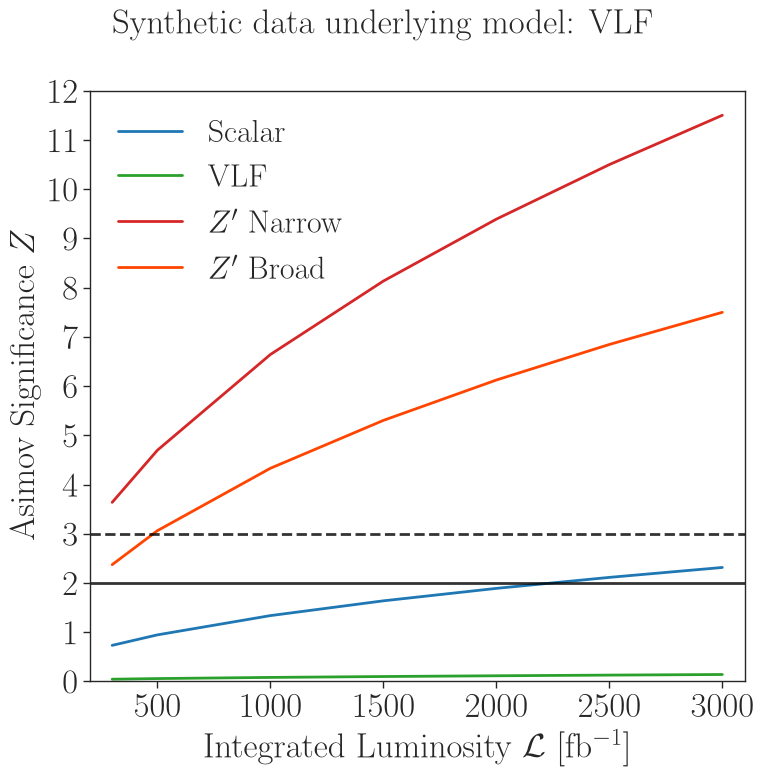

In [25]:
true_model_labels = {
    'Scalar_1500': 'Scalar',
    'VLF_1500': 'VLF',
    'Zprime_3000': r'$Z^\prime$ Broad',
    'Zprime_1pc_3000': r'$Z^\prime$ Narrow',
    'SM': 'SM',
}
plot_lumi_syst_combined(
    results=results_df,
    eps_values=systematics,
    outfile=f'AsimovSignificance_vs_Lumi_{active_fake_data}.png',
    metric='sh',
    fake_model=true_model_labels.get(active_fake_data, active_fake_data),
)


# Summary plot for stats only

In [26]:
# Summary significance table at 3 ab^-1 for every BSM truth and SM truth.
summary_lumi = np.array([3000.0])
dict_z_hl = {}
for fake_key in [*benchmark_keys, 'SM']:
    print(f'Summary significance: truth={fake_key} at L={summary_lumi[0]:g} fb^-1')
    fitted = {summary_lumi[0]: make_fitted_data(fake_key, summary_lumi[0])}
    labels = benchmark_keys if fake_key == 'SM' else fit_hypothesis_labels
    dict_z_hl[fake_key] = hp.run_fast_lumi_scan(
        fitted_data_by_lumi=fitted, labels=labels,
        lumi_targets=summary_lumi, sys_err_list=systematics,
        fake_model='FakeData', sm_cms=False,
        include_sm=(fake_key != 'SM'),
        observable='pT', analysis_range=analysis_range,
    )


Summary significance: truth=Zprime_3000 at L=3000 fb^-1

Fitting observable: pT
Analysis range: 500 <= pT < 3600 GeV
Systematic error: 0.0%
VLF         : selected mass = 1500.000 GeV | parabolic estimate = 1517.585 GeV | scale = 3.501678 | min q = 67.2678 | source = grid
Scalar      : selected mass = 1300.000 GeV | parabolic estimate = 1336.120 GeV | scale = 5.8579555 | min q = 60.0134 | source = grid
Zprime      : selected mass = 2900.000 GeV | parabolic estimate = 2918.955 GeV | scale = -0.49779238 | min q = 59.9048 | source = grid
Zprime_20pc : selected mass = 3000.000 GeV | parabolic estimate = 3009.792 GeV | scale = -4.4019003 | min q = 0.00502694 | source = grid
FakeData    : nominal mass = 3000.0 GeV | scale = -4.4
Synthetic signal yield in fit window: 8266.50 events
Summary significance: truth=Zprime_1pc_3000 at L=3000 fb^-1

Fitting observable: pT
Analysis range: 500 <= pT < 3600 GeV
Systematic error: 0.0%
VLF         : selected mass = 1500.000 GeV | parabolic estimate = 1487.

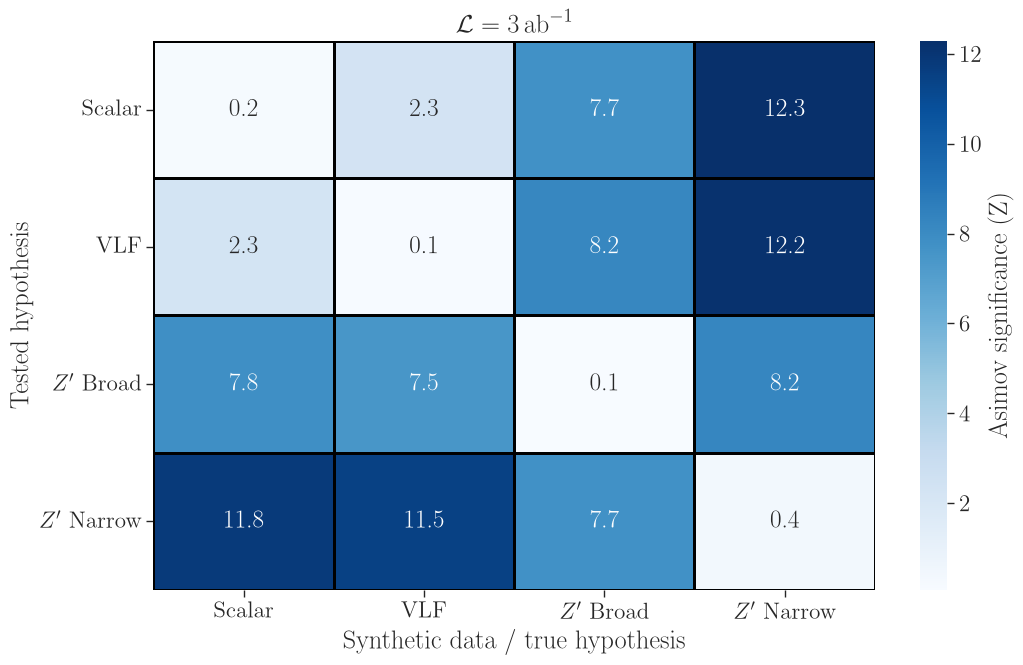

In [30]:
# Shape-significance heatmap. Each cell keeps its truth/test orientation.
truth_labels = {
    'Scalar_1500': 'Scalar', 'VLF_1500': 'VLF',
    'Zprime_3000': r"$Z^\prime$ Broad",
    'Zprime_1pc_3000': r"$Z^\prime$ Narrow",
    'SM': 'SM',
}
model_labels = {
    'Scalar': 'Scalar', 'VLF': 'VLF',
    'Zprime': r"$Z^\prime$ Narrow",
    'Zprime_20pc': r"$Z^\prime$ Broad",
    'SM': 'SM',
    **{key: truth_labels[key] for key in benchmark_keys},
}


summary_col = f"Z_sh_eps_{int(round(100 * systematics[0])):02d}"
summary_matrix = {}
for fake_key, df in dict_z_hl.items():
    col_name = truth_labels.get(fake_key, fake_key)
    summary_matrix[col_name] = {}
    for _, row in df.iterrows():
        tested_key = str(row['pair']).split(' vs ', 1)[-1]
        test_label = model_labels.get(tested_key, tested_key)
        summary_matrix[col_name][test_label] = float(row[summary_col])

model_order = [
    'Scalar', 
    'VLF',
    r'$Z^\prime$ Broad',
    r'$Z^\prime$ Narrow',
]

df_significance = pd.DataFrame(summary_matrix)
df_significance = df_significance.reindex(index=model_order, columns=model_order)
plt.figure(figsize=(11, 7))
ax = sns.heatmap(
    df_significance, annot=True, fmt='.1f', cmap='Blues',
    cbar_kws={'label': 'Asimov significance (Z)'},
    linewidths=1, linecolor='black',
)
plt.yticks(rotation=0)
plt.title(r'$\mathcal{L}=3\,\mathrm{ab}^{-1}$')
plt.xlabel('Synthetic data / true hypothesis')
plt.ylabel('Tested hypothesis')
plt.tight_layout()
plt.savefig('Summary_plot_stats_with_SM_and_narrow_Zprime.png', bbox_inches='tight', dpi=300)
plt.show()


The summary matrix above includes the new narrow $Z^\prime$ benchmark and an SM-truth column. For the SM column, each hypothesis is a **fixed** benchmark rather than a best-fit model.


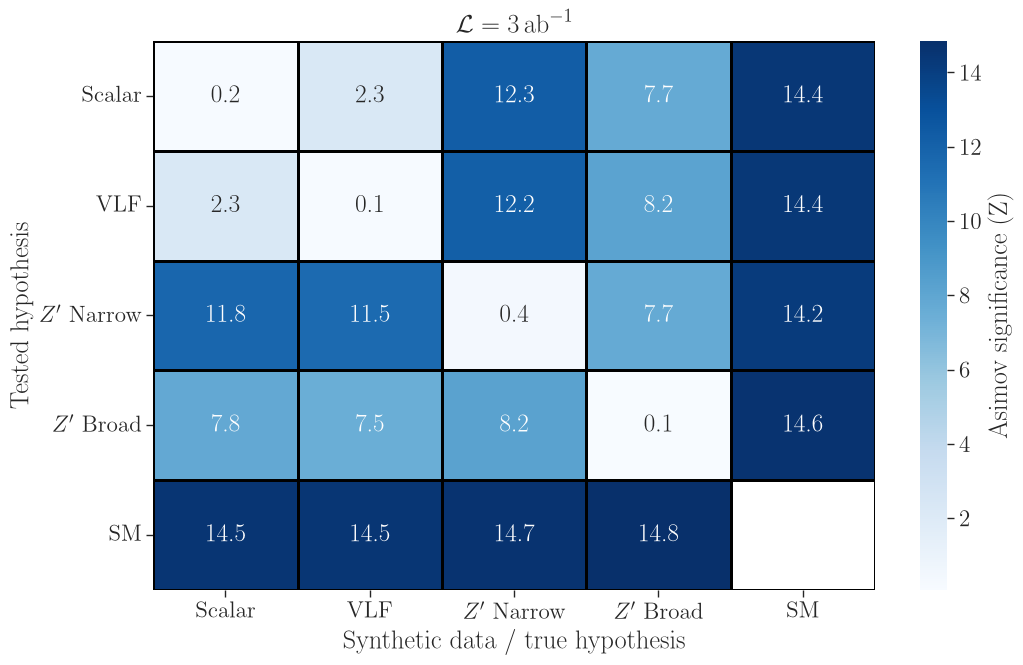

In [29]:
# Shape-significance heatmap. Each cell keeps its truth/test orientation.
truth_labels = {
    'Scalar_1500': 'Scalar', 'VLF_1500': 'VLF',
    'Zprime_3000': r"$Z^\prime$ Broad",
    'Zprime_1pc_3000': r"$Z^\prime$ Narrow",
    'SM': 'SM',
}
model_labels = {
    'Scalar': 'Scalar', 'VLF': 'VLF',
    'Zprime': r"$Z^\prime$ Narrow",
    'Zprime_20pc': r"$Z^\prime$ Broad",
    'SM': 'SM',
    **{key: truth_labels[key] for key in benchmark_keys},
}


summary_col = f"Z_sh_eps_{int(round(100 * systematics[0])):02d}"
summary_matrix = {}
for fake_key, df in dict_z_hl.items():
    col_name = truth_labels.get(fake_key, fake_key)
    summary_matrix[col_name] = {}
    for _, row in df.iterrows():
        tested_key = str(row['pair']).split(' vs ', 1)[-1]
        test_label = model_labels.get(tested_key, tested_key)
        summary_matrix[col_name][test_label] = float(row[summary_col])

model_order = [
    'Scalar',
    'VLF',
    r'$Z^\prime$ Narrow',
    r'$Z^\prime$ Broad',
    'SM'
]

df_significance = pd.DataFrame(summary_matrix)
df_significance = df_significance.reindex(index=model_order, columns=model_order)
plt.figure(figsize=(11, 7))
ax = sns.heatmap(
    df_significance, annot=True, fmt='.1f', cmap='Blues',
    cbar_kws={'label': 'Asimov significance (Z)'},
    linewidths=1, linecolor='black',
)
plt.yticks(rotation=0)
plt.title(r'$\mathcal{L}=3\,\mathrm{ab}^{-1}$')
plt.xlabel('Synthetic data / true hypothesis')
plt.ylabel('Tested hypothesis')
plt.tight_layout()
#plt.savefig('Summary_plot_stats_with_SM_and_narrow_Zprime.png', bbox_inches='tight', dpi=300)
plt.show()


In [13]:

import pickle

with open(workspace_file, 'rb') as handle:
    ws = pickle.load(handle)

model_names = ['Scalar', 'VLF', 'Zprime', 'Zprime_20pc']

for fake_key in ws['FakeData']:
    print(f'\n{fake_key}')
    for model_name in model_names:
        samples = ws.get('BestFitSamples', {}).get(fake_key, {}).get(model_name, {})
        if samples:
            print(f'  {model_name:15s}: OK      masses = {sorted(samples)}')
        else:
            print(f'  {model_name:15s}: MISSING')



Zprime_3000
  Scalar         : MISSING
  VLF            : MISSING
  Zprime         : MISSING
  Zprime_20pc    : MISSING

Zprime_1pc_3000
  Scalar         : MISSING
  VLF            : MISSING
  Zprime         : MISSING
  Zprime_20pc    : MISSING

Scalar_1500
  Scalar         : MISSING
  VLF            : MISSING
  Zprime         : MISSING
  Zprime_20pc    : MISSING

VLF_1500
  Scalar         : MISSING
  VLF            : MISSING
  Zprime         : MISSING
  Zprime_20pc    : MISSING
